# 03 — feature engineering

raw features aren't always the best features. this notebook adds interaction terms, fixes skewness, and scales everything before modelling.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from src.features import log_transform, add_interaction_features, scale_features, get_skewed_cols

sns.set_theme(style='whitegrid')

df = pd.read_csv('../data/processed/california_clean.csv')
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## step 1 — add interaction features

raw `AveRooms` and `Population` aren't that informative on their own. ratios make more sense.

In [2]:
df = add_interaction_features(df)
print("new columns added:", ['rooms_per_household', 'bedrooms_per_room', 'population_per_household'])
df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe().round(3)

new columns added: ['rooms_per_household', 'bedrooms_per_room', 'population_per_household']


,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000,20640.000,20640.000
mean,1.936,0.213,493.847
std,0.644,0.058,342.670
min,0.312,0.100,2.000
25%,1.523,0.176,280.956
50%,1.938,0.204,410.000
75%,2.296,0.239,606.000
max,14.960,1.000,3851.802


## step 2 — fix skewed features

log-transforming skewed columns makes them more normal, which helps linear models a lot.

In [3]:
feature_cols = [c for c in df.columns if c != 'price']

skewed = get_skewed_cols(df[feature_cols], threshold=0.75)
print(f"skewed columns (|skew| > 0.75): {skewed}")

skewed columns (|skew| > 0.75): ['MedInc', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']


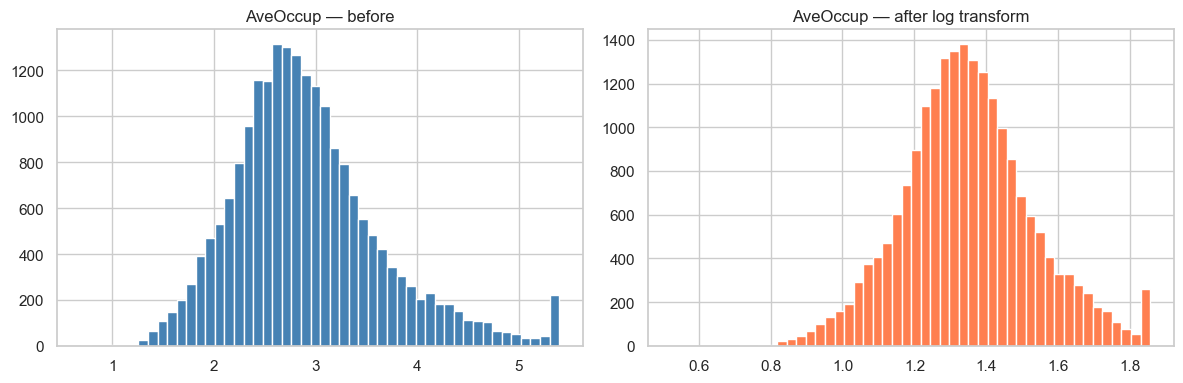

In [4]:
# visualize before/after for one skewed column
col = 'AveOccup'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[col], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title(f'{col} — before')

axes[1].hist(np.log1p(df[col]), bins=50, color='coral', edgecolor='white')
axes[1].set_title(f'{col} — after log transform')

plt.tight_layout()
plt.savefig('../plots/log_transform_example.png', dpi=120)
plt.show()

In [5]:
df = log_transform(df, skewed)
print("applied log1p to:", skewed)

applied log1p to: ['MedInc', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']


## step 3 — train/test split

split before scaling — scaler is fit only on training data.

In [6]:
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"train: {X_train.shape}  test: {X_test.shape}")

train: (16512, 11)  test: (4128, 11)


## step 4 — scale features

In [7]:
X_train_scaled, X_test_scaled, scaler = scale_features(X_train, X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("mean (should be ~0):", X_train_scaled.mean(axis=0).round(3))
print("std  (should be ~1):", X_train_scaled.std(axis=0).round(3))

X_train_scaled shape: (16512, 11)
mean (should be ~0): [-0. -0. -0.  0.  0.  0.  0.  0.  0. -0.  0.]
std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## save engineered data

In [8]:
# save train/test splits for use in modelling notebooks
X_train_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_df  = pd.DataFrame(X_test_scaled,  columns=X_test.columns)

X_train_df['price'] = y_train.values
X_test_df['price']  = y_test.values

X_train_df.to_csv('../data/processed/train.csv', index=False)
X_test_df.to_csv('../data/processed/test.csv',   index=False)

print("saved train.csv and test.csv")

saved train.csv and test.csv


## correlation heatmap — after feature engineering

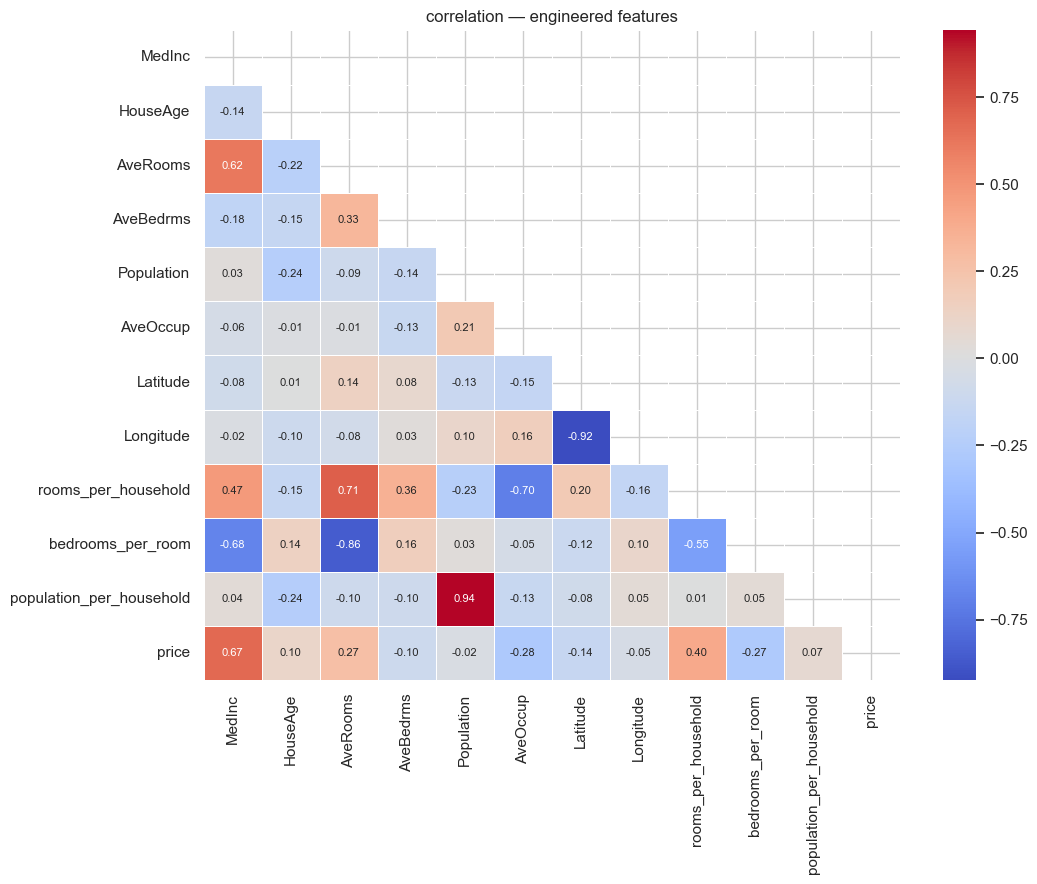

In [9]:
plt.figure(figsize=(11, 9))
corr = pd.concat([X_train_df.drop(columns=['price']), y_train.reset_index(drop=True)], axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, annot_kws={'size': 8})
plt.title('correlation — engineered features')
plt.tight_layout()
plt.savefig('../plots/correlation_engineered.png', dpi=120)
plt.show()

**`rooms_per_household`** ends up more correlated with price than the raw `AveRooms` — that's the whole point of interaction features.